# ExpTM — author-followup preflight

This notebook checks supplied data and prepares corrected training inputs. It does **not** train a model, sample a diffusion model, or simulate new MCMC data. Existing experimental results remain unchanged.

Open this notebook from the extracted `ExpTM_Author_Followup` directory. Dependencies: NumPy and Matplotlib. Run cells in order. Saved outputs below were generated during preparation.

## Source and scope

- Author repository commit: `bc55961331ff94a48e51974d9f537319ace96e9c`.
- Author Colab: https://colab.research.google.com/drive/1Q5-LyumxZfZc6aHt71ZKOsGWfjrGEEzV
- Read-only retrieval: 2026-11-09. Original Colab is preserved alongside this notebook.
- Author email: physical training data at T=7, chemical potentials -16 and 0; mapped prior controls; recommendation to train from scratch for 5–10 epochs.
- The previous 11x11 result was public-checkpoint inference only: 121 points, 16 samples each; temperature controls 2..10 and mean controls -1..1. Its physical axes and checkpoint provenance were not established.

The old Colab repository URL redirects to `tiwarylab/ExpTM`. Its old `ExpTM_GC/thermomaps-root` working directory is absent from the pinned current tree. The present source directory is `GC_Lattice_gas/expTM_data_genenration`; data are in the sibling `data` directory.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
assert (ROOT / 'asset_manifest.json').is_file(), 'Open/run from the extracted ExpTM_Author_Followup folder.'
manifest = json.loads((ROOT / 'asset_manifest.json').read_text())
for asset in manifest['assets']:
    path = ROOT / 'author_snapshot' / asset['path']
    data = path.read_bytes()
    git_blob_sha = hashlib.sha1(b'blob ' + str(len(data)).encode() + b'\0' + data).hexdigest()
    assert len(data) == asset['size'] and git_blob_sha == asset['sha'], path
print('Verified all four downloaded arrays against pinned Git blob hashes.')
DATA = ROOT / 'author_snapshot/GC_Lattice_gas/data'
low = np.load(DATA / 'LowMuT7.npy', allow_pickle=False)
high = np.load(DATA / 'HighMuT7.npy', allow_pickle=False)
for name, array in [('low', low), ('high', high)]:
    assert array.ndim == 4 and array.shape[1] == 2
    assert np.isfinite(array).all()
    assert set(np.unique(array[:, 0])).issubset({-1.0, 1.0})
    rho = (array[:, 0] > 0).mean(axis=(1, 2))
    print(name, 'shape:', array.shape, 'stored channel 1:', np.unique(array[:, 1]),
          'mean density:', float(rho.mean()))


Verified all four downloaded arrays against pinned Git blob hashes.
low shape: (5000, 2, 20, 20) stored channel 1: [-4.] mean density: 0.048104499999999994
high shape: (5000, 2, 20, 20) stored channel 1: [4.] mean density: 0.9515275


## Correct sample counts and channel roles

The retrieved Colab allocates 20,000 labels and uses blocks of 10,000. The current files each contain 5,000 configurations, so this would cause a shape mismatch. We derive labels from actual array lengths.

The intermediate stored labels -4/+4 are overwritten in the Colab. The actual training controls are -1/+1 and temperature-control 1. `chemicalP_conversion` is defined but not called in this workflow; its definition alone does not establish the physical-axis conversion.

The following cell prepares inputs only. It preserves the Colab's channel ordering and uses float64 like its `np.zeros` construction. The author Loader later converts to torch float32 and adds dequantization noise.


In [2]:
assert low.shape[1:] == high.shape[1:]
n_low, n_high = len(low), len(high)
mean_controls = np.repeat([-1.0, 1.0], [n_low, n_high])
temperature_controls = np.ones(n_low + n_high)
training_data = np.empty((n_low + n_high, 3, *low.shape[-2:]), dtype=np.float64)
training_data[:, 0] = np.concatenate([low[:, 0], high[:, 0]])
training_data[:, 1] = temperature_controls[:, None, None]
training_data[:, 2] = mean_controls[:, None, None]
assert len(training_data) == len(mean_controls) == len(temperature_controls)
print('Prepared:', training_data.shape)
print('Channel 0: spin coordinate; channel 1: temperature control; channel 2: prior-mean control.')
print('Temperature controls:', np.unique(temperature_controls))
print('Mean controls and counts:', np.unique(mean_controls, return_counts=True))


Prepared: (10000, 3, 20, 20)
Channel 0: spin coordinate; channel 1: temperature control; channel 2: prior-mean control.
Temperature controls: [1.]
Mean controls and counts: (array([-1.,  1.]), array([5000, 5000]))


## Training-data snapshots

These are supplied MCMC data, not newly generated expTM samples. Histograms summarize the supplied configurations; they are not estimates of uncertainty across independent simulations.


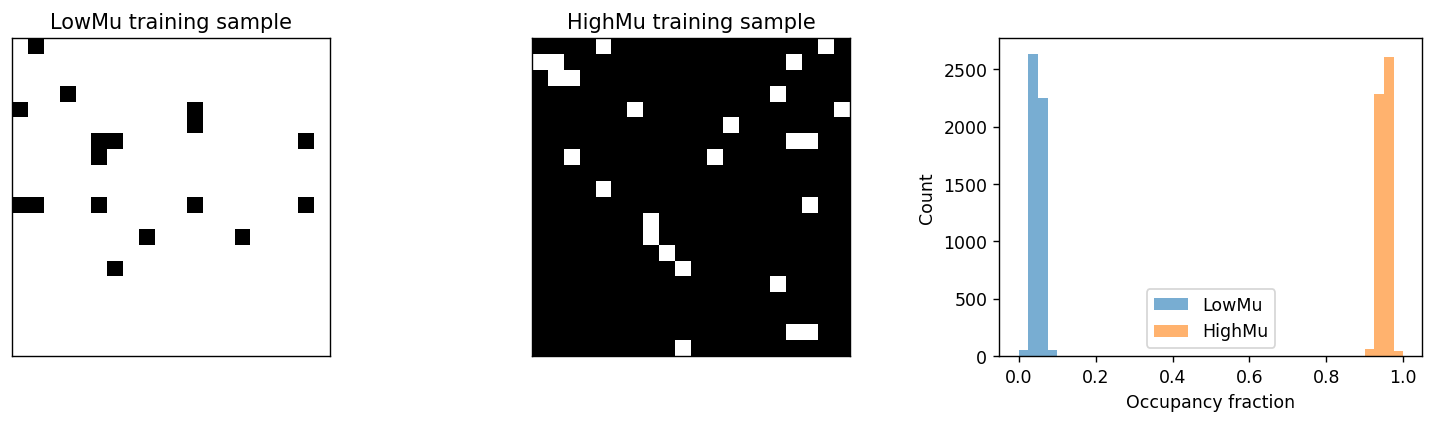

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, array, name in zip(axes[:2], [low, high], ['LowMu training sample', 'HighMu training sample']):
    ax.imshow(array[0, 0], cmap='binary', vmin=-1, vmax=1, interpolation='nearest')
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
for array, name in [(low, 'LowMu'), (high, 'HighMu')]:
    axes[2].hist((array[:, 0] > 0).mean(axis=(1, 2)), bins=np.linspace(0, 1, 41),
                 alpha=0.6, label=name)
axes[2].set_xlabel('Occupancy fraction'); axes[2].set_ylabel('Count')
axes[2].legend()
plt.tight_layout()
plt.show()


## Author reference matrices

The author's plotting notebook uses a 25x25 generated-density matrix and the first 25x25 entries of a 26x26 reference matrix, with displayed axes mu=-20..4 and T=1..13. We reproduce that slicing explicitly below. The reference's extra row/column and exact sample-coordinate convention need provenance clarification before a new pointwise physical comparison.

This is a replot of author-supplied arrays, **not our reproduction result**. All plots use the same density scale. A full mapping from prior controls to these physical axes has not been located in the retrieved Colab.


Reference shape: (26, 26)
Generated shape: (25, 25)


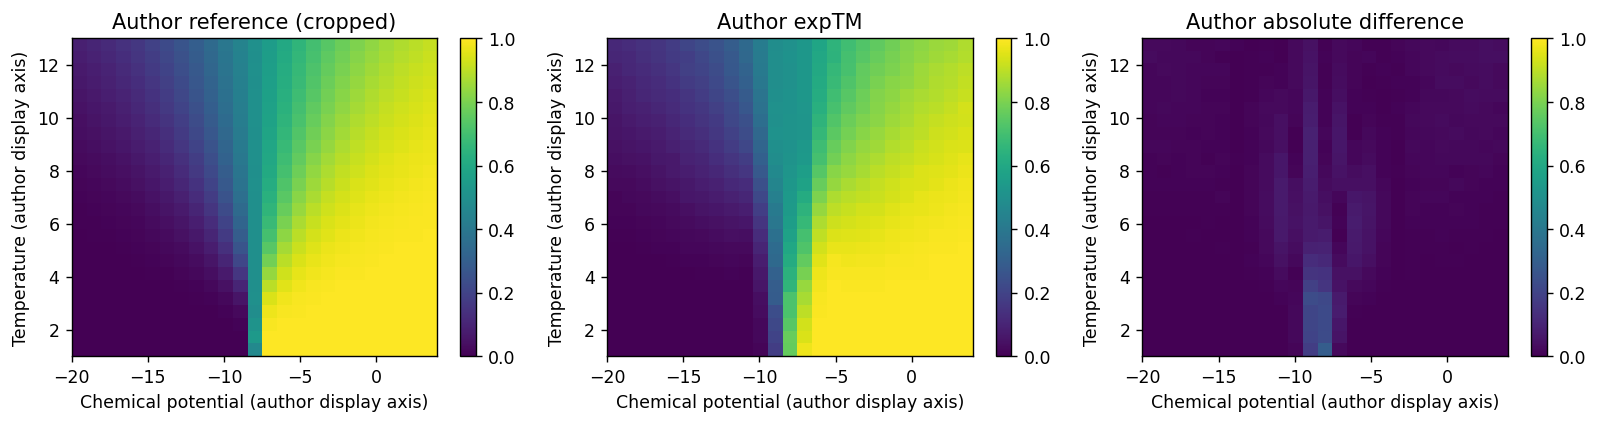

In [4]:
FIG_DATA = ROOT / 'author_snapshot/GC_Lattice_gas/manuscript_figure'
author_reference = np.load(FIG_DATA / 'org_density_matrix.npy', allow_pickle=False)
author_generated = np.load(FIG_DATA / 'density_matrix.npy', allow_pickle=False)
print('Reference shape:', author_reference.shape)
print('Generated shape:', author_generated.shape)
assert author_reference.shape == (26, 26) and author_generated.shape == (25, 25)
reference_view = author_reference[:25, :25]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, matrix, title in zip(axes, [reference_view, author_generated,
                                   np.abs(reference_view - author_generated)],
                            ['Author reference (cropped)', 'Author expTM', 'Author absolute difference']):
    im = ax.imshow(matrix, origin='lower', aspect='auto', extent=[-20, 4, 1, 13],
                   vmin=0, vmax=1, cmap='viridis')
    ax.set_title(title); ax.set_xlabel('Chemical potential (author display axis)')
    ax.set_ylabel('Temperature (author display axis)')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()
